# 2. Looking at the Kelmarsh data

The same questions as notebook 1, now for the wind turbines: how much data is
there, how complete is it, and are the failures visible in the sensors?

Kelmarsh is a wind farm of six Senvion MM92 turbines in Northamptonshire. We use
2017. Unlike MetroPT-3 there is a status log with an event for every stop, so we
can count failures instead of reading them from a PDF.

In [1]:
import zipfile

import pandas as pd
from matplotlib import pyplot as plt

DATA = '../data/Kelmarsh_SCADA_2017_3083.zip'
TURBINES = [1, 2, 3, 4, 5, 6]

## Loading

The zip holds two files per turbine: `Turbine_Data_...` with sensor readings
every 10 minutes, and `Status_...` with the operating log.

In [2]:
with zipfile.ZipFile(DATA) as z:
    for name in z.namelist():
        print(name)

Turbine_Data_Kelmarsh_1_2017-01-01_-_2018-01-01_228.csv
Status_Kelmarsh_1_2017-01-01_-_2018-01-01_228.csv
Turbine_Data_Kelmarsh_2_2017-01-01_-_2018-01-01_229.csv
Status_Kelmarsh_2_2017-01-01_-_2018-01-01_229.csv
Turbine_Data_Kelmarsh_3_2017-01-01_-_2018-01-01_230.csv
Status_Kelmarsh_3_2017-01-01_-_2018-01-01_230.csv
Turbine_Data_Kelmarsh_4_2017-01-01_-_2018-01-01_231.csv
Status_Kelmarsh_4_2017-01-01_-_2018-01-01_231.csv
Turbine_Data_Kelmarsh_5_2017-01-01_-_2018-01-01_232.csv
Status_Kelmarsh_5_2017-01-01_-_2018-01-01_232.csv
Turbine_Data_Kelmarsh_6_2017-01-01_-_2018-01-01_233.csv
Status_Kelmarsh_6_2017-01-01_-_2018-01-01_233.csv


Things to know before calling `read_csv`:

- Each file starts with **9 comment lines** (turbine name, time zone, export date).
  `skiprows=9` jumps over them.
- The timestamp column is called `# Date and time`, hash included.
- In the status log, events that were still open when the file was exported have
  `-` as end time. `na_values='-'` turns that into a missing value.
- The README says the files are not UTF-8. For this archive they are: the degree
  sign is stored as UTF-8, and reading with `latin-1` turns every `°C` into `Â°C`,
  so the column names no longer match. We use pandas' default, UTF-8.

In [3]:
def read_file(kind, turbine):
    '''Read one CSV from the zip. kind is 'Turbine_Data' or 'Status'.'''
    with zipfile.ZipFile(DATA) as z:
        prefix = f'{kind}_Kelmarsh_{turbine}_'
        name = [n for n in z.namelist() if n.startswith(prefix)][0]
        with z.open(name) as f:
            return pd.read_csv(f, skiprows=9, na_values='-')

## The sensor data

We start with turbine 1 to see what a single file looks like.

In [4]:
data = read_file('Turbine_Data', 1)
print(f'{len(data):,} rows, {data.shape[1]} columns including the timestamp')

data['# Date and time'] = pd.to_datetime(data['# Date and time'])
data = data.set_index('# Date and time')

step = data.index.to_series().diff()

print(f'from {data.index.min()} to {data.index.max()}')
print(f'median gap between rows: {step.median()}')

52,560 rows, 299 columns including the timestamp
from 2017-01-01 00:00:00 to 2017-12-31 23:50:00
median gap between rows: 0 days 00:10:00


One row every 10 minutes for the whole year, which is the resolution we chose for
MetroPT-3, so no aggregation is needed here.

## How complete is it?

299 columns is a lot, but many are statistics (max, min, standard deviation) of
the same sensor, and many of those were never filled in. The timestamp is now
the index, so the counts below are over the 298 sensor columns.

In [5]:
coverage = data.notna().mean()

print(f'more than 90 % filled: {(coverage > 0.9).sum()} columns')
print(f'completely empty:      {(coverage == 0).sum()} columns')
print(f'somewhere in between:  {((coverage > 0) & (coverage <= 0.9)).sum()} columns')

more than 90 % filled: 104 columns
completely empty:      137 columns
somewhere in between:  57 columns


We only need a handful of columns: the three bearing temperatures named in the
literature on wind turbine condition monitoring, and power and wind speed, which
tell us how hard the turbine is working.

In [6]:
sensors = ['Front bearing temperature (°C)',
           'Rear bearing temperature (°C)',
           'Generator bearing rear temperature (°C)',
           'Power (kW)',
           'Wind speed (m/s)']

coverage[sensors].round(3)

Front bearing temperature (°C)             0.988
Rear bearing temperature (°C)              0.988
Generator bearing rear temperature (°C)    0.988
Power (kW)                                 0.988
Wind speed (m/s)                           0.988
dtype: float64

About 98.8 % complete. The missing 1.2 % is whole rows, so it is periods where
the turbine logged nothing at all.

## The status log

Every turbine has its own log. We read all six into one table and compute the
duration ourselves from start and end. The `Duration` column in the file uses
hours above 24 (for example `548:13:20`), which pandas cannot parse.

In [7]:
logs = []
for turbine in TURBINES:
    log = read_file('Status', turbine)
    log['turbine'] = turbine
    logs.append(log)

status = pd.concat(logs, ignore_index=True)
status['start'] = pd.to_datetime(status['Timestamp start'])
status['end'] = pd.to_datetime(status['Timestamp end'])
status['hours'] = (status['end'] - status['start']).dt.total_seconds() / 3600

print(f'{len(status):,} log lines across {len(TURBINES)} turbines')
status[['turbine', 'start', 'end', 'Status', 'Message', 'IEC category']].head()

49,132 log lines across 6 turbines


,turbine,start,end,Status,Message,IEC category
0,1,2016-12-17 16:38:07,2017-01-09 12:51:27,Warning,Timeout brake closed,NaN
1,1,2017-01-02 06:55:53,2017-01-02 06:58:10,Stop,Battery test,Technical Standby
2,1,2017-01-05 11:18:28,2017-01-05 11:19:15,Informational,Wind < start wind,Out of Environmental Specification
3,1,2017-01-05 11:18:28,2017-01-05 11:28:29,Stop,Hydraulic oil flushing operation,Technical Standby
4,1,2017-01-07 01:16:37,2017-01-07 13:00:39,Communication,Data communication unavailable,NaN


Two columns describe each line. `Status` is how severe it is, `IEC category` is
what the time counts as under the IEC availability standard. A cross table shows
both at once.

In [8]:
pd.crosstab(status['IEC category'], status['Status'], margins=True)

Status,Informational,Stop,Warning,All
IEC category,,,,
Forced outage,0,122,54,176
Full Performance,29501,0,42,29543
Out of Electrical Specification,0,87,0,87
Out of Environmental Specification,11248,16,0,11264
Requested Shutdown,0,12,0,12
Scheduled Maintenance,0,147,0,147
Technical Standby,7108,449,0,7557
All,47857,833,96,48786


Most lines are `Informational`. **Forced outage** is the category we want: an
unplanned stop caused by a fault. That is our failure label. `Scheduled
Maintenance` is planned work and `Out of Environmental Specification` is mostly
too little wind, so neither counts as a failure.

Note that forced outages include `Warning` lines and not only `Stop` lines. We
checked all of them against the power column: in almost every one the turbine
produces zero power for the whole duration, so they are real stops and we keep them.

In [9]:
forced = status[status['IEC category'] == 'Forced outage']

per_turbine = forced.groupby('turbine').agg(
    log_lines=('Message', 'size'),
    total_hours=('hours', 'sum'),
    longest_hours=('hours', 'max'),
)
per_turbine.round(1)

,log_lines,total_hours,longest_hours
turbine,,,
1,38,71.7,11.5
2,23,20.4,3.8
3,16,18.6,4.3
4,27,20.8,4.2
5,24,44.8,20.5
6,48,154.3,110.4


## Log lines are not failures

One fault often writes several lines at once. The clearest example is
"Overload generator fan 1", "... fan 2" and "... fan 3", which always appear
together within a few seconds. Counting those as three failures would be wrong.

So we merge lines that overlap in time on the same turbine into one **event**.

In [10]:
def merge_overlapping(log):
    '''Join log lines that overlap in time into one event per fault.'''
    events = []
    for row in log.sort_values('start').itertuples():
        if events and row.start <= events[-1]['end']:
            events[-1]['end'] = max(events[-1]['end'], row.end)
            events[-1]['lines'] += 1
        else:
            events.append({'start': row.start, 'end': row.end,
                           'message': row.Message, 'lines': 1})
    return pd.DataFrame(events)


merged = []
for turbine in TURBINES:
    ev = merge_overlapping(forced[forced['turbine'] == turbine])
    ev['turbine'] = turbine
    merged.append(ev)

events = pd.concat(merged, ignore_index=True)
events['hours'] = ((events['end'] - events['start']).dt.total_seconds() / 3600).round(1)

per_turbine['events'] = events.groupby('turbine').size()
per_turbine.round(1)

,log_lines,total_hours,longest_hours,events
turbine,,,,
1,38,71.7,11.5,31
2,23,20.4,3.8,19
3,16,18.6,4.3,10
4,27,20.8,4.2,23
5,24,44.8,20.5,17
6,48,154.3,110.4,41


What kinds of faults are they? The first message of each event:

In [11]:
events['message'].value_counts()

message
Frequency converter not ready       24
Tower oscillation Y level 1         19
Pitch run-away (hub box v.>=4)      17
Tower oscillation X level 1         15
Tower oscillation X level 2         14
High rotor speed nacelle             9
Tower oscillation Y level 2          8
Overload generator fan 1             7
Manual stop - remote                 5
Limit switch error 95° axis 3        4
Limit switch error 95° axis 1        3
Overload generator fan 3             3
Safety chain open                    3
Limit switch error 95° axis 2        2
Uncontrolled yaw movement            2
Rotor sensor A defective             1
Overload yaw motor 1&3               1
Yaw speed high                       1
Vane defect                          1
Disc filter adaption implausible     1
Frequency converter error            1
Name: count, dtype: int64

Many are not things a bearing temperature could warn about. "Tower oscillation"
and "High rotor speed" are the control system stopping the turbine in strong,
gusty wind. "Frequency converter" and "Pitch run-away" are electrical and pitch
system faults. These are protective stops, not worn components.

## The whole year

We plot the bearing temperatures, power and wind speed for one turbine, with
its ten longest forced outages shaded. Most outages last a few hours, which is
very thin on a year-long axis, so we draw an edge around each shaded area to
keep it visible.

In [12]:
def load_turbine(turbine):
    '''Sensor data for one turbine, only the columns we use.'''
    d = read_file('Turbine_Data', turbine)
    d.index = pd.to_datetime(d['# Date and time'])
    return d[sensors]


def mark_outages(ax, turbine_events):
    '''Shade forced outage events on a plot.'''
    for row in turbine_events.itertuples():
        ax.axvspan(row.start, row.end, color='sandybrown', alpha=0.5, lw=1)


def plot_year(turbine):
    d = load_turbine(turbine)
    longest = events[events['turbine'] == turbine].nlargest(10, 'hours')

    fig, axes = plt.subplots(len(sensors), 1, figsize=(12, 1.6 * len(sensors)),
                             sharex=True)
    for ax, name in zip(axes, sensors):
        ax.plot(d.index, d[name], lw=0.3)
        ax.set_ylabel(name.replace(' temperature', ' temp.'), fontsize=7)
        mark_outages(ax, longest)

    axes[0].set_title(f'Kelmarsh {turbine}, 2017. Shaded = 10 longest forced outages')
    plt.tight_layout()

Turbine 6 has the most events and the single longest outage of the farm.

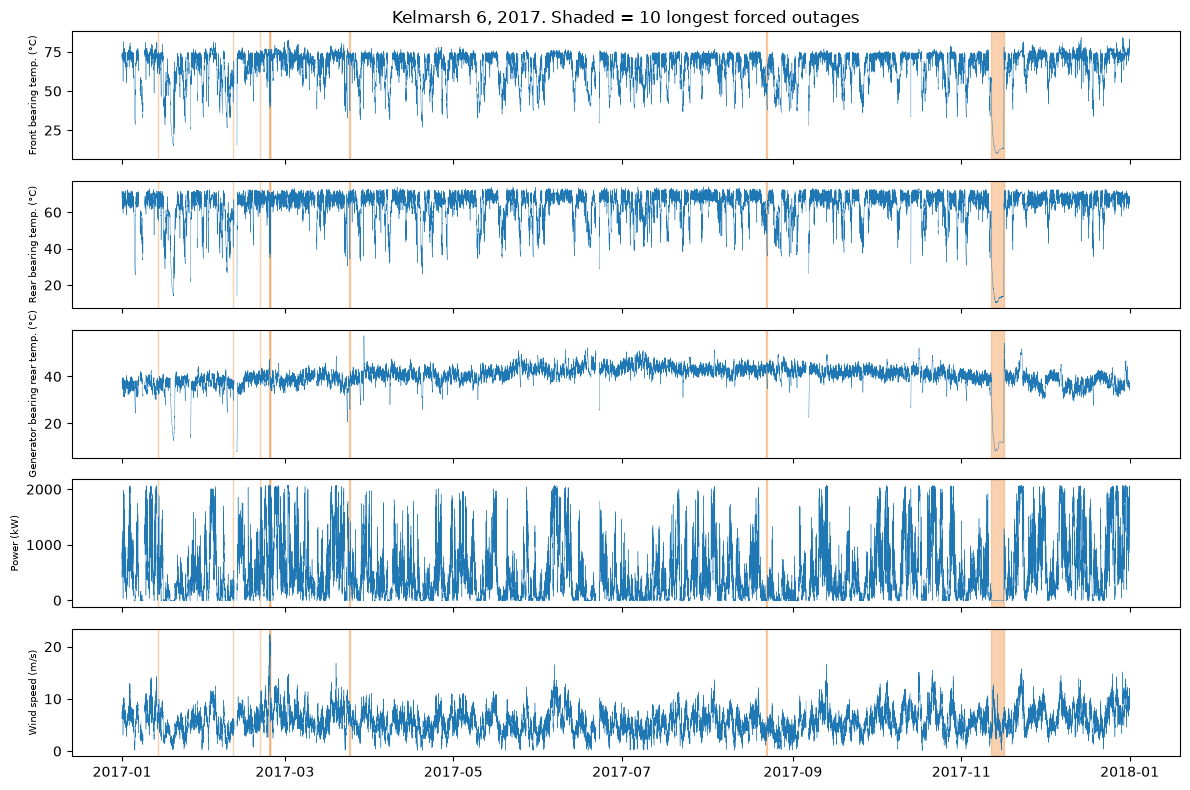

In [13]:
plot_year(6)

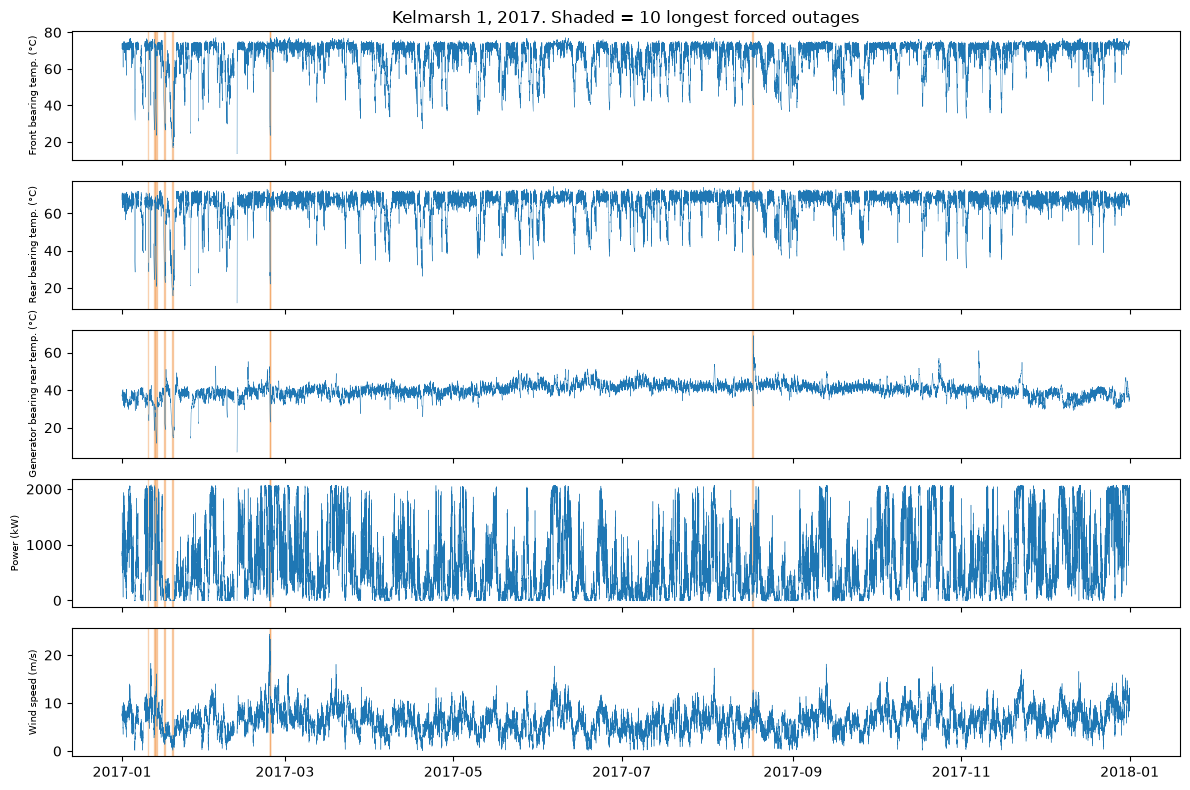

In [14]:
plot_year(1)

The front and rear bearing temperatures sit on a ceiling of about 70–75 °C
whenever the turbine produces power, and drop towards the outside temperature
when it stands still. They follow the load, not the season. The generator bearing
does the opposite: it follows the season, and only cools slowly during a long
stop such as the one in November.

One thing does stand out on turbine 1: the generator bearing jumps to about 65 °C
in mid-August, at a "generator fan overload" outage. Looking at the numbers, the
jump comes right *after* the turbine restarts, not before it stops, which fits
the fans not cooling properly. It is not an early warning.

Otherwise nothing jumps out ahead of the shaded periods at this scale, so we zoom in.

## A closer look at the longest outages

The four longest events across all six turbines, from two days before until half a
day after.

In [15]:
longest = events.nlargest(4, 'hours')
longest[['turbine', 'start', 'hours', 'lines', 'message']]

,turbine,start,hours,lines,message
139,6,2017-11-11 20:05:53,110.4,1,Frequency converter error
97,5,2017-06-21 16:10:53,20.5,3,Limit switch error 95° axis 1
8,1,2017-01-13 02:42:10,11.5,1,High rotor speed nacelle
15,1,2017-01-18 23:19:38,11.4,1,High rotor speed nacelle


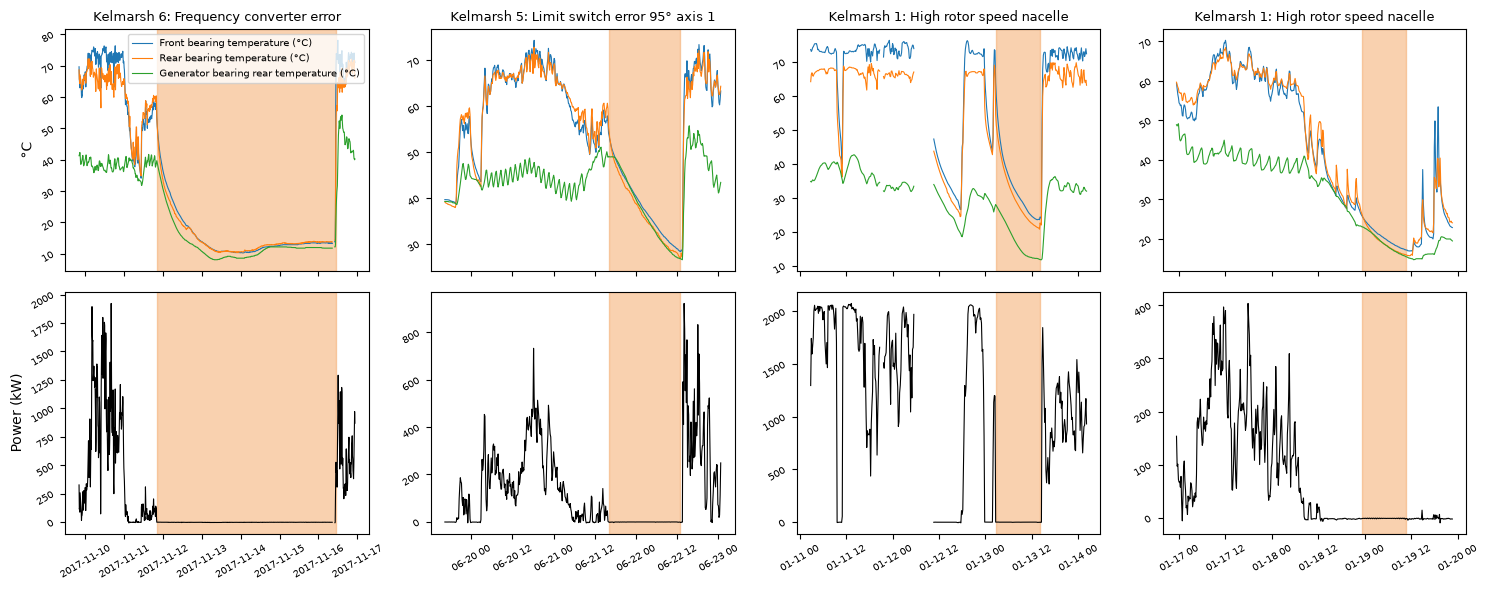

In [16]:
temperatures = sensors[:3]
data_by_turbine = {t: load_turbine(t) for t in longest['turbine'].unique()}

fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex='col')

for i, row in enumerate(longest.itertuples()):
    d = data_by_turbine[row.turbine]
    window = d.loc[row.start - pd.Timedelta(days=2): row.end + pd.Timedelta(hours=12)]

    for name in temperatures:
        axes[0, i].plot(window.index, window[name], lw=0.8, label=name)
    axes[1, i].plot(window.index, window['Power (kW)'], lw=0.8, color='black')

    for ax in axes[:, i]:
        ax.axvspan(row.start, row.end, color='sandybrown', alpha=0.5)
        ax.tick_params(labelsize=7, rotation=30)
    axes[0, i].set_title(f'Kelmarsh {row.turbine}: {row.message}', fontsize=9)

axes[0, 0].set_ylabel('°C')
axes[1, 0].set_ylabel('Power (kW)')
axes[0, 0].legend(fontsize=7)
plt.tight_layout()

Before every one of these stops the bearing temperatures move together with
power: up when the wind picks up, down when it drops. Once the turbine stops they
cool off steadily. We see no rise that power does not already explain.

## Temperature relative to load

Since bearing temperature depends so much on power, the fair question is not "is it
hot?" but "is it hotter than usual **for this power**?". We plot every 10-minute
reading of the front bearing against power, and mark the 24 hours before each of
the four events.

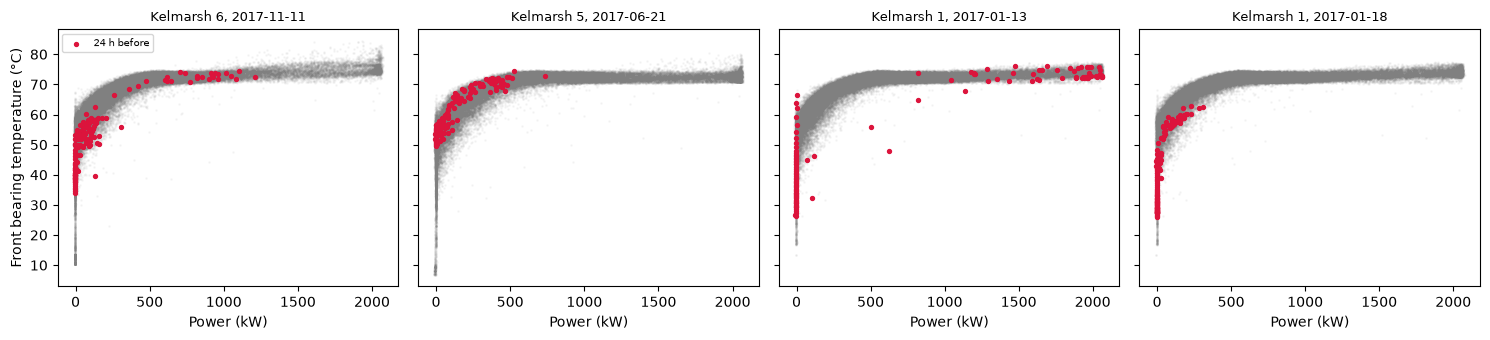

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
front = 'Front bearing temperature (°C)'

for ax, row in zip(axes, longest.itertuples()):
    d = data_by_turbine[row.turbine]
    before = d.loc[row.start - pd.Timedelta(hours=24): row.start]

    ax.scatter(d['Power (kW)'], d[front], s=1, alpha=0.05, color='grey')
    ax.scatter(before['Power (kW)'], before[front], s=8, color='crimson',
               label='24 h before')
    ax.set_title(f'Kelmarsh {row.turbine}, {row.start.date()}', fontsize=9)
    ax.set_xlabel('Power (kW)')

axes[0].set_ylabel(front)
axes[0].legend(fontsize=7)
plt.tight_layout()

The red points sit inside the grey cloud, or below it where the turbine was still
warming up after an earlier stop. In the day before these outages the front
bearing was never hotter than it normally is at the same power.

## What we learned

**The data is clean and easy to use.** 52 560 rows per turbine, one every 10
minutes, no aggregation needed. 104 of the 298 sensor columns are over 90 % filled
(105 of 299 counting the timestamp), and the ones we need are 98.8 % complete.

**Forced outages are a label, but not one failure each.** Turbine 1 has 38
forced outage lines, but simultaneous lines describe one fault. Merging
overlapping lines turns 176 lines across the farm into 141 events, 31 of them on
turbine 1. They are short: three quarters
of the log lines last under an hour, the median is 16 minutes. Only one, a
frequency converter fault on turbine 6 in November, lasts days.

**Most forced outages are not wear.** The common causes are tower oscillation,
high rotor speed, pitch faults and converter errors. These are protective stops
in rough weather or electrical faults, which a bearing thermometer has no reason
to see coming.

**The textbook signal is not there, at least not for these four.** Bearing
temperatures follow power before every long outage, and are not hotter than usual
for the load in the day before. A real bearing failure in 2017 would have shown
up as a long outage, and there is none.

**What this means for the detector.** Raw temperature is mostly a picture of
power and wind. A detector should look at temperature *given* power (the KDE on
several sensors at once does this), or it will just flag windy days. We should
also expect that many forced outages are undetectable from these sensors. That
does not mean the method fails; it means we should report recall per fault type
rather than one overall number.

Open questions and choices are in `DECISIONS.md`.